# Clustering Track
**Dataset:** UCI *Multiple Features* (mfeat): 2,000 handwritten digits (0-9, 200 each) from Dutch utility maps, described by six feature sets, 649 features in total.

**Pipeline:** standardise → PCA (50 components) → spectral embedding of a k-nearest-neighbour graph → cluster. The embedding settings are chosen without labels (Section 3).

**Algorithms:** K-Means (elbow curve to choose k) and Agglomerative Hierarchical clustering (dendrogram, comparison of linkage strategies).

**Metrics:** Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index for every algorithm; PCA (2 components) plots for every algorithm; t-SNE plot.

**Rule:** the digit labels (implied by row order) are **never** passed to a fit. They are used only after clustering, to validate the result (ARI, NMI, contingency tables).

In [1]:
# Make the project's src/ package importable from notebooks/
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 80)

## 1. Load and combine the six feature sets

In [2]:
from src import config as C, data_loader as dl, clustering as clu, visualize as viz

X_raw, y_true, feat_names = dl.load_mfeat()   # y_true kept aside for post-hoc checks only
print('Shape:', X_raw.shape, ' Missing values:', int(np.isnan(X_raw).sum()))
pd.DataFrame({'File': [f'mfeat-{s}' for s in C.MFEAT_SETS],
              'Description': [C.MFEAT_DESC[s] for s in C.MFEAT_SETS]})

Shape: (2000, 649)  Missing values: 0


,File,Description
0,mfeat-fou,Fourier coefficients (76)
1,mfeat-fac,Profile correlations (216)
2,mfeat-kar,Karhunen-Loeve coefficients (64)
3,mfeat-pix,Pixel averages 2x3 windows (240)
4,mfeat-zer,Zernike moments (47)
5,mfeat-mor,Morphological features (6)


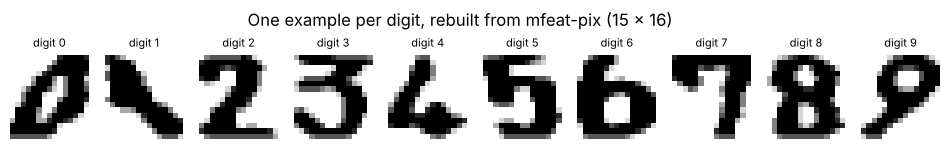

In [3]:
fig, axes = plt.subplots(1, 10, figsize=(12, 1.8))
for d, ax in enumerate(axes):
    ax.imshow(dl.pixel_image(d * 200 + 5), cmap='gray_r'); ax.set_title(f'digit {d}', fontsize=8); ax.axis('off')
fig.suptitle('One example per digit, rebuilt from mfeat-pix (15 x 16)');

## 2. Preprocessing
The six feature blocks are standardised (zero mean, unit variance), because both algorithms use Euclidean distances and the blocks are on very different scales.

In [4]:
print('Value range per block before scaling:')
start = 0
for s in C.MFEAT_SETS:
    w = int(C.MFEAT_DESC[s].split('(')[1].rstrip(')'))
    print(f'  {s}: {X_raw[:, start:start+w].min():9.2f} to {X_raw[:, start:start+w].max():9.2f}')
    start += w
X, scaler = clu.scale(X_raw)
print('After scaling: mean', X.mean().round(6), ' std', X.std().round(3))

Value range per block before scaling:
  fou:      0.00 to      0.80
  fac:      0.00 to   1353.00
  kar:    -16.46 to     17.05
  pix:      0.00 to      6.00
  zer:      0.00 to    777.86
  mor:      0.00 to  17572.20
After scaling: mean -0.0  std 1.0


## 3. Why cluster in a reduced space?
### 3a. Baseline: clustering the 649 scaled features directly
This is the first version of the pipeline, kept for comparison. In 649 dimensions Euclidean distances become very similar to each other (curse of dimensionality), so every point is almost equally far from every cluster. Single linkage suffers most: it merges the two *closest* points between clusters, so a chain of in-between digits links everything into one cluster.

In [5]:
K = C.K_FINAL
baseline_labels = clu.all_labels(X, K)
baseline = pd.DataFrame([{'Algorithm': n, **clu.internal_metrics(X, l),
                          'Largest cluster': np.bincount(l).max(), 'Smallest cluster': np.bincount(l).min()}
                         for n, l in baseline_labels.items()])
baseline

,Algorithm,Silhouette,Davies-Bouldin,Calinski-Harabasz,Largest cluster,Smallest cluster
0,K-Means,0.1325,2.2376,145.2921,247,164
1,Agglomerative (ward),0.1286,2.2943,139.3618,234,174
2,Agglomerative (complete),0.0660,2.5599,86.9448,483,29
3,Agglomerative (average),0.0888,1.5535,61.0417,968,1
4,Agglomerative (single),-0.0160,0.8118,1.5586,1991,1


### 3b. Dimensionality reduction: PCA → spectral embedding
1. **PCA to 50 components** removes low-variance, noisy directions.
2. **Spectral embedding** builds a graph that joins each digit to its `n_neighbors` nearest digits, and maps the points so that digits connected through the graph sit close together. Digits of the same class form a connected group, so each class becomes a compact blob.
3. **Unit-length rows** (Ng-Jordan-Weiss normalisation) put every point on a sphere, which sharpens the separation between groups.

The two settings (`n_components`, `n_neighbors`) are chosen by a grid search that uses **no labels**: each setting is scored by the mean silhouette of all five algorithms in the embedded space. Takes about 30 seconds.

In [6]:
search = clu.tune_embedding(X, K)
best = search.iloc[0]
N_COMP, N_NEIGH = int(best['n_components']), int(best['n_neighbors'])
print(f'chosen: n_components = {N_COMP}, n_neighbors = {N_NEIGH}')
search.head(8)

chosen: n_components = 8, n_neighbors = 15


,n_components,n_neighbors,mean silhouette,min silhouette,K-Means,Agglomerative (ward),Agglomerative (complete),Agglomerative (average),Agglomerative (single)
0,8,15,0.6942,0.2119,0.8487,0.8403,0.7253,0.8448,0.2119
1,9,15,0.6879,0.0340,0.8550,0.8492,0.8505,0.8506,0.0340
2,8,10,0.6771,0.0828,0.8310,0.8263,0.8206,0.8247,0.0828
3,9,20,0.6594,-0.0687,0.8449,0.8405,0.8386,0.8416,-0.0687
4,9,10,0.6480,-0.1606,0.8543,0.8493,0.8471,0.8499,-0.1606
5,9,30,0.6410,-0.0820,0.8279,0.8199,0.8182,0.8212,-0.0820
6,8,20,0.6307,-0.0647,0.8322,0.8299,0.7786,0.7774,-0.0647
7,8,30,0.5812,-0.1998,0.8144,0.8109,0.7394,0.7413,-0.1998


In [7]:
Z = clu.embed(X, N_COMP, N_NEIGH)   # every model below is fitted on Z
print('Embedded data:', Z.shape)

Embedded data: (2000, 8)


## 4. K-Means: elbow curve (inertia vs. k)
K-Means is fitted on the embedded data `Z` for k = 2 to 15. The table also shows silhouette per k, the percentage drop in inertia from the previous k, and an automatic knee estimate (point farthest from the line joining the curve's endpoints). The value of k used below is set in `src/config.py` (`K_FINAL`).

In [8]:
elbow = clu.elbow_analysis(Z)
elbow['inertia drop %'] = (-elbow['inertia'].pct_change() * 100).round(2)
k_auto = clu.find_elbow(elbow['k'], elbow['inertia'])
k_sil = int(elbow.loc[elbow['silhouette'].idxmax(), 'k'])
print(f'automatic knee = {k_auto}, best silhouette = {k_sil}, k used = {K}')
elbow

automatic knee = 9, best silhouette = 10, k used = 10


,k,inertia,silhouette,inertia drop %
0,2,1730.8216,0.1934,NaN
1,3,1488.5055,0.2794,14.00
2,4,1211.0149,0.3789,18.64
3,5,1000.5459,0.4627,17.38
4,6,788.9561,0.5494,21.15
5,7,561.8754,0.6356,28.78
6,8,360.7517,0.7162,35.80
7,9,195.1059,0.7794,45.92
8,10,75.0199,0.8487,61.55
9,11,66.6806,0.8263,11.12


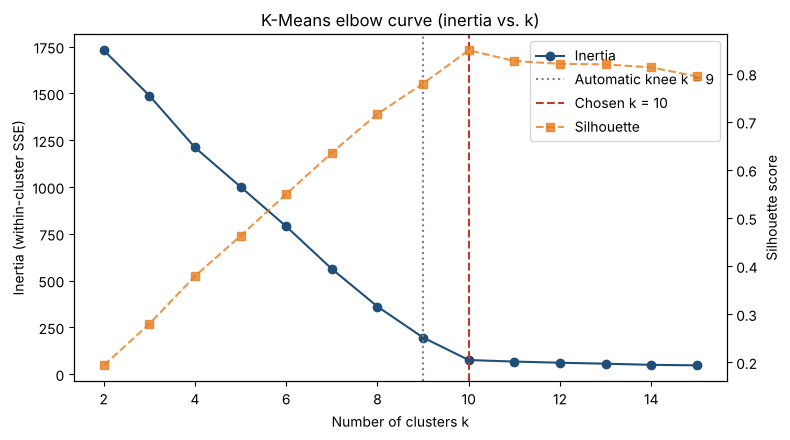

In [9]:
viz.elbow_plot(elbow, K, k_auto=k_auto);

Sensitivity check: both algorithms at each candidate k (ARI/NMI are post-hoc only).

In [10]:
sens = []
for kk in sorted({k_auto, k_sil, K}):
    for algo, lab in (('K-Means', clu.fit_kmeans(Z, kk).labels_),
                      ('Agglomerative (ward)', clu.fit_agglomerative(Z, kk).labels_)):
        sens.append({'k': kk, 'Algorithm': algo, **clu.internal_metrics(Z, lab),
                     **clu.external_validation(y_true, lab)})
pd.DataFrame(sens)

,k,Algorithm,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI,NMI
0,9,K-Means,0.7794,0.5234,2298.8771,0.8484,0.9069
1,9,Agglomerative (ward),0.7769,0.5265,2246.5655,0.8460,0.9060
2,10,K-Means,0.8487,0.2428,5665.7032,0.9352,0.9326
3,10,Agglomerative (ward),0.8403,0.2608,5056.9096,0.9256,0.9285


> **✍️ Team observation — write this in your own words before submission.**
>
> Questions to answer:
> - Where is the elbow in the curve? Is it sharp or gradual?
> - Justify the value of k you use. What evidence supports it (elbow, silhouette, domain knowledge)?
> - How do the metrics in the sensitivity table change with k?
>
> _Your answer here._

In [11]:
km = clu.fit_kmeans(Z, K)
pd.Series(clu.internal_metrics(Z, km.labels_))

Silhouette              0.8487
Davies-Bouldin          0.2428
Calinski-Harabasz    5665.7032
dtype: float64

## 5. Agglomerative hierarchical clustering: comparing linkage strategies
Four linkages at the same k: **ward** (minimises the increase in within-cluster variance), **complete** (maximum pairwise distance), **average** (mean pairwise distance) and **single** (minimum pairwise distance). Cluster sizes are shown alongside the metrics.

In [12]:
link_table, agg_models = clu.compare_linkages(Z, K)
link_table

,Linkage,Silhouette,Davies-Bouldin,Calinski-Harabasz,Largest cluster,Smallest cluster
0,ward,0.8403,0.2608,5056.9096,222,182
1,complete,0.7253,0.8598,1460.9997,399,10
2,average,0.8448,0.2466,5326.6771,224,180
3,single,0.2119,1.1324,226.4003,598,1


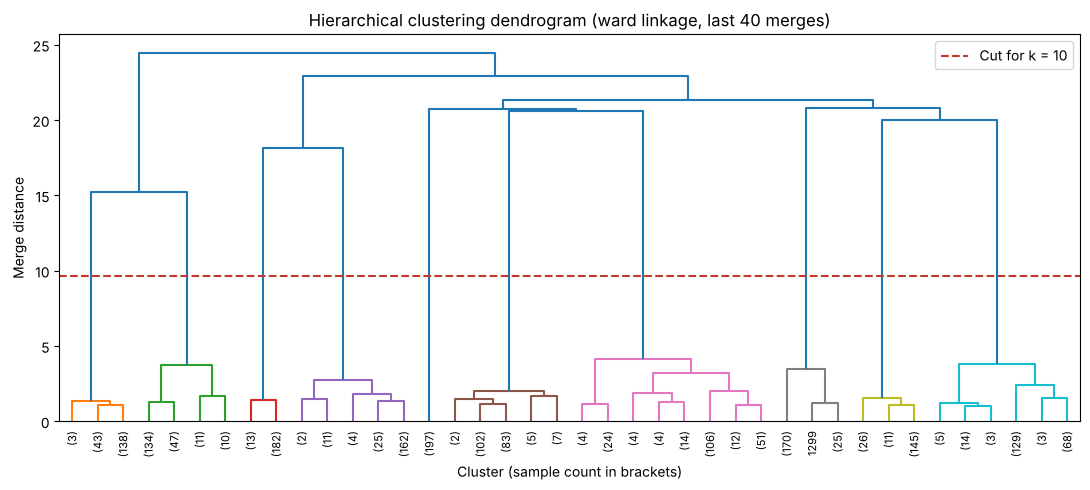

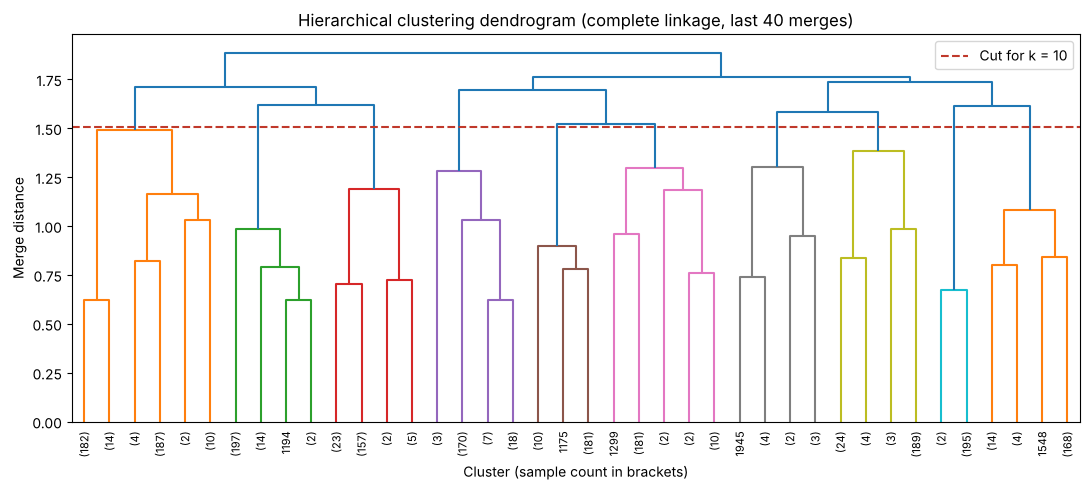

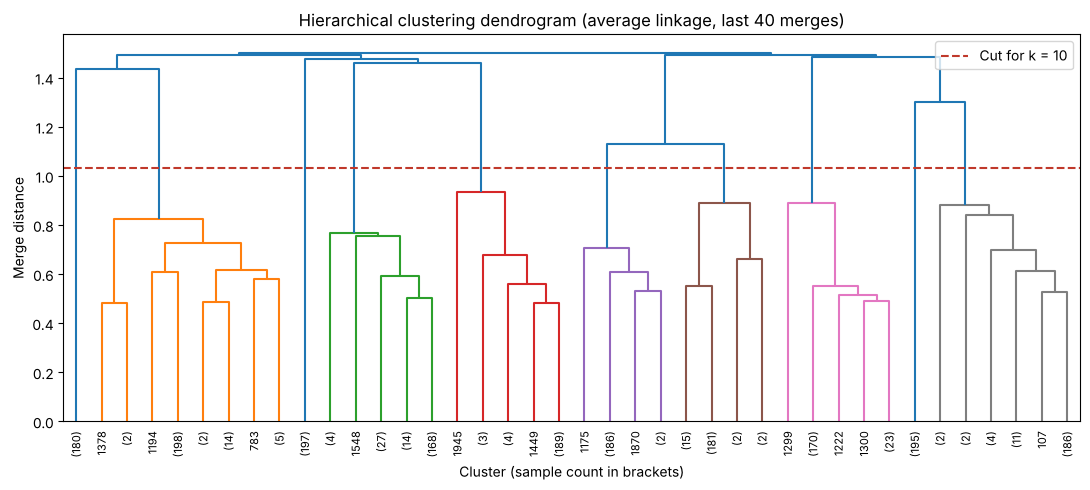

In [13]:
for method in ['ward', 'complete', 'average']:
    viz.dendrogram_plot(clu.linkage_matrix(Z, method), K, method)

> **✍️ Team observation — write this in your own words before submission.**
>
> Questions to answer:
> - Compare the four linkages: metrics and cluster sizes. Which would you choose and why?
> - Does any metric look good for a linkage whose clusters are clearly poor? What does that tell you?
> - What does the dendrogram show around the cut for your chosen k?
>
> _Your answer here._

## 6. Evaluation: all three metrics for every algorithm

In [14]:
all_labels = {'K-Means': km.labels_, **{f'Agglomerative ({lk})': m.labels_ for lk, m in agg_models.items()}}
metrics = pd.DataFrame([{'Algorithm': n, **clu.internal_metrics(Z, l)} for n, l in all_labels.items()])
metrics

,Algorithm,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,K-Means,0.8487,0.2428,5665.7032
1,Agglomerative (ward),0.8403,0.2608,5056.9096
2,Agglomerative (complete),0.7253,0.8598,1460.9997
3,Agglomerative (average),0.8448,0.2466,5326.6771
4,Agglomerative (single),0.2119,1.1324,226.4003


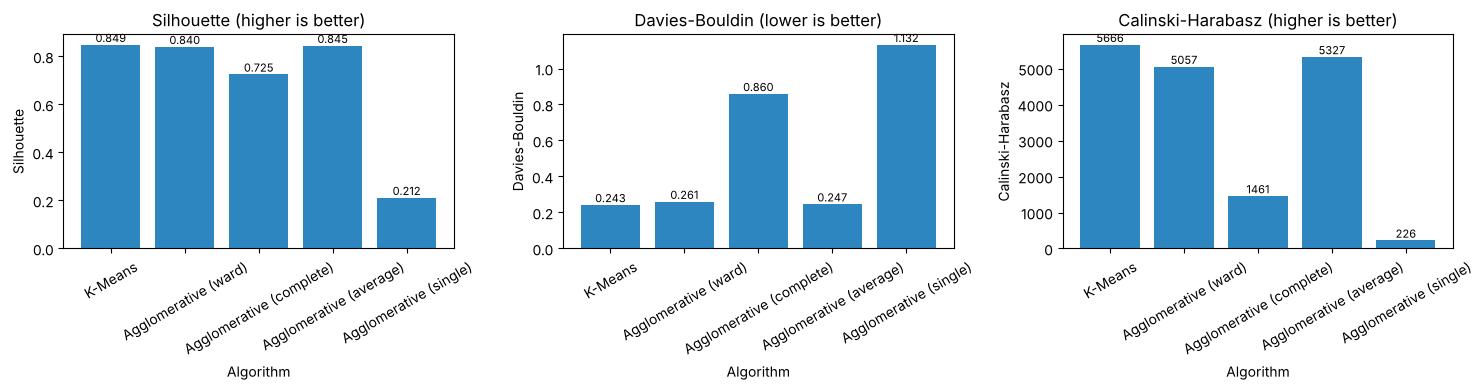

In [15]:
viz.metric_bars(metrics, 'Algorithm');

### Before vs after dimensionality reduction
Same algorithms, same k. Each model is scored in the space it was fitted in.

In [16]:
compare = baseline.set_index('Algorithm')[['Silhouette', 'Davies-Bouldin', 'Calinski-Harabasz']].join(
    metrics.set_index('Algorithm'), lsuffix=' (before)', rsuffix=' (after)')
compare[sorted(compare.columns, key=lambda c: (c.split(' (')[0], 'after' in c))]

,Calinski-Harabasz (before),Calinski-Harabasz (after),Davies-Bouldin (before),Davies-Bouldin (after),Silhouette (before),Silhouette (after)
Algorithm,,,,,,
K-Means,145.2921,5665.7032,2.2376,0.2428,0.1325,0.8487
Agglomerative (ward),139.3618,5056.9096,2.2943,0.2608,0.1286,0.8403
Agglomerative (complete),86.9448,1460.9997,2.5599,0.8598,0.0660,0.7253
Agglomerative (average),61.0417,5326.6771,1.5535,0.2466,0.0888,0.8448
Agglomerative (single),1.5586,226.4003,0.8118,1.1324,-0.0160,0.2119


| Metric | Meaning | Better |
|---|---|---|
| Silhouette | How much closer a point is to its own cluster than to the nearest other cluster (−1 to 1) | higher |
| Davies-Bouldin | Average ratio of within-cluster spread to between-cluster separation | lower |
| Calinski-Harabasz | Between-cluster dispersion ÷ within-cluster dispersion | higher |

> **✍️ Team observation — write this in your own words before submission.**
>
> Questions to answer:
> - How do K-Means and the chosen Agglomerative model compare on the three metrics?
> - Are the absolute silhouette values high or low? What could explain that for this data?
>
> _Your answer here._

## 7. Visualisation: PCA (2 components) for every algorithm
PCA of the embedded data `Z`, the space the clusters were found in.

Variance explained by PC1 + PC2: 0.312


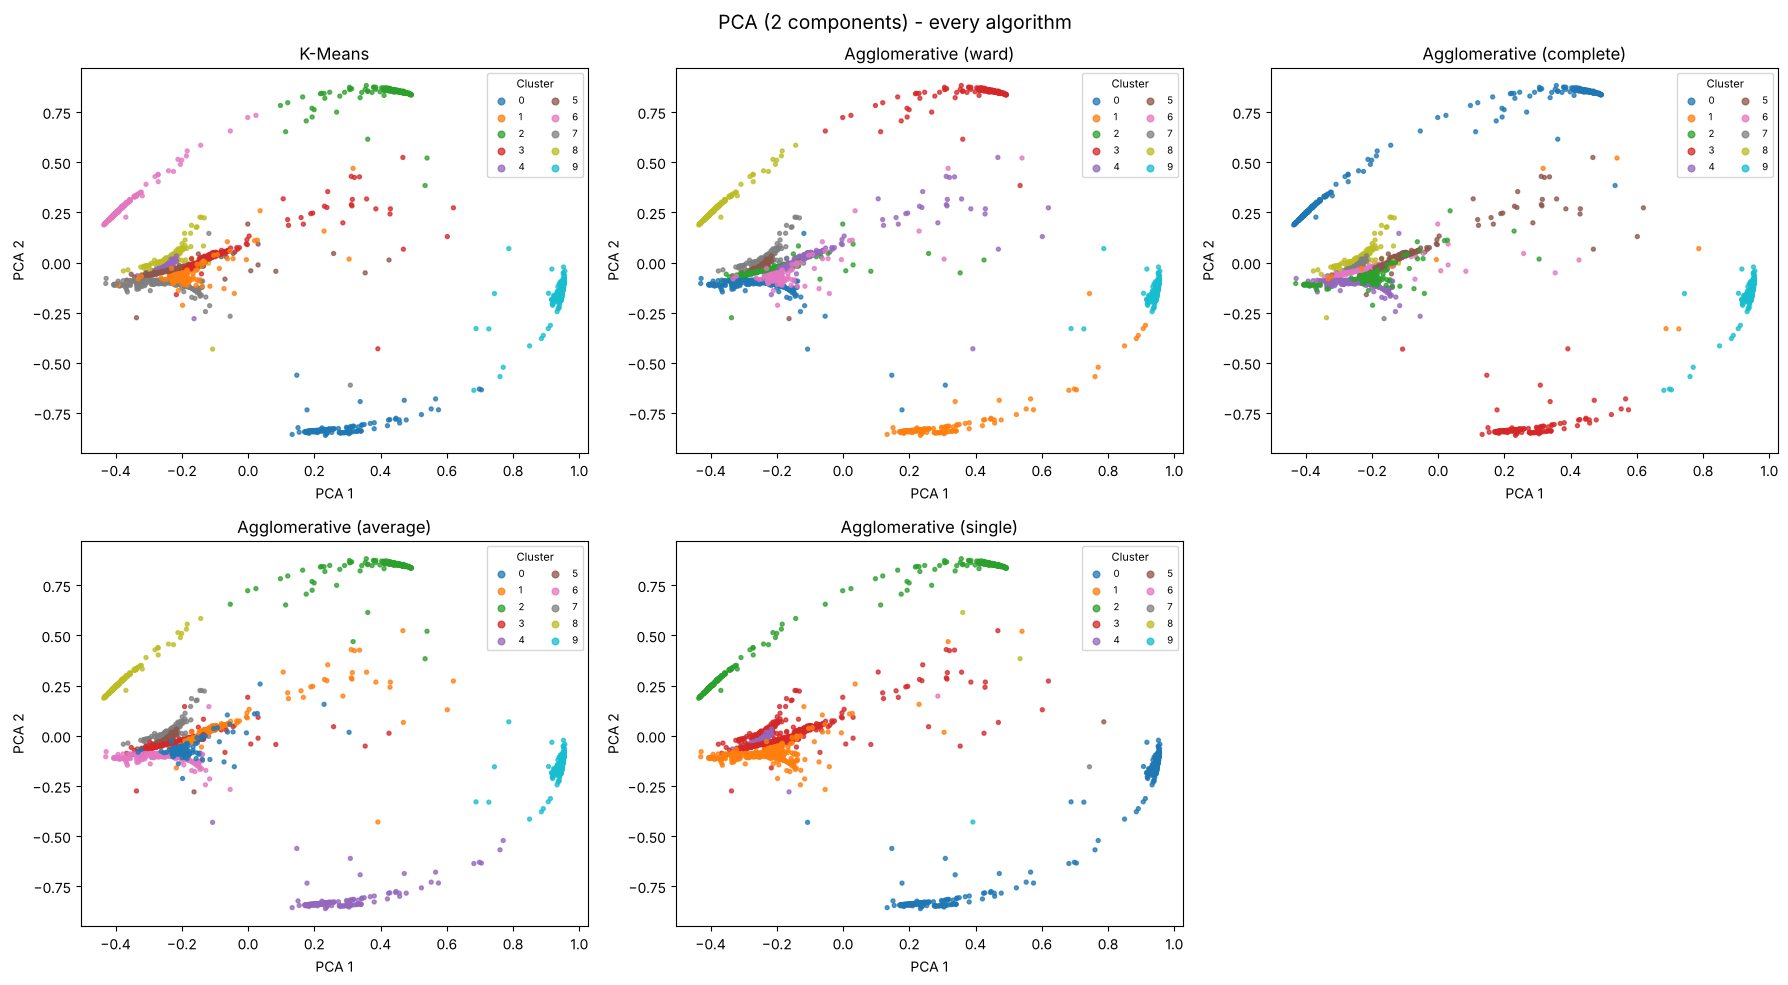

In [17]:
pca_xy, pca = clu.pca_2d(Z)
print('Variance explained by PC1 + PC2:', pca.explained_variance_ratio_.sum().round(3))
viz.scatter_grid(pca_xy, all_labels, 'PCA', 'PCA (2 components) - every algorithm');

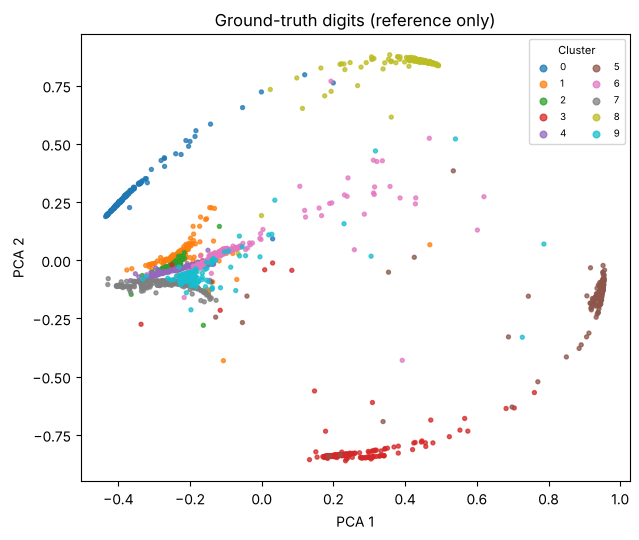

In [18]:
viz.scatter_clusters(pca_xy, y_true, 'Ground-truth digits (reference only)');

## 8. Visualisation: t-SNE
The 649 scaled features are reduced to 50 PCA components first, then embedded with t-SNE (perplexity 30).

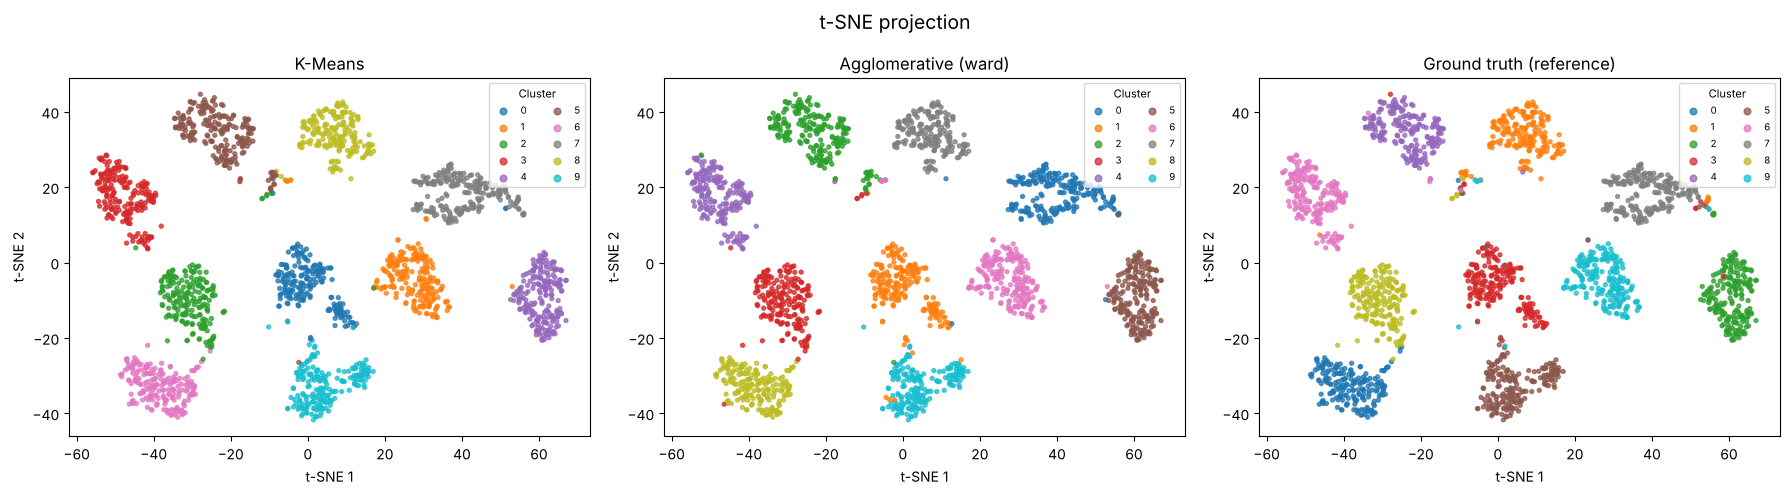

In [19]:
tsne_xy = clu.tsne_2d(X)
viz.scatter_grid(tsne_xy, {'K-Means': km.labels_, 'Agglomerative (ward)': agg_models['ward'].labels_,
                           'Ground truth (reference)': y_true}, 't-SNE', 't-SNE projection');

> **✍️ Team observation — write this in your own words before submission.**
>
> Questions to answer:
> - How do the PCA and t-SNE views differ, and why? (Consider how much variance 2 PCA components keep.)
> - Which clusters are well separated and which overlap?
>
> _Your answer here._

## 9. Post-hoc validation against the true digits
Only now are the labels used: **ARI** (Adjusted Rand Index; 0 = random, 1 = perfect) and **NMI** (Normalized Mutual Information), plus a cluster × digit contingency table.

In [20]:
ext = pd.DataFrame([{'Algorithm': n, **clu.external_validation(y_true, l)} for n, l in all_labels.items()])
before = pd.DataFrame([{'Algorithm': n, **clu.external_validation(y_true, l)} for n, l in baseline_labels.items()])
metrics.merge(ext, on='Algorithm').merge(before, on='Algorithm', suffixes=('', ' (before)'))

,Algorithm,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI,NMI,ARI (before),NMI (before)
0,K-Means,0.8487,0.2428,5665.7032,0.9352,0.9326,8.3764e-01,0.8569
1,Agglomerative (ward),0.8403,0.2608,5056.9096,0.9256,0.9285,9.0256e-01,0.9116
2,Agglomerative (complete),0.7253,0.8598,1460.9997,0.8143,0.8833,2.9624e-01,0.4914
3,Agglomerative (average),0.8448,0.2466,5326.6771,0.9317,0.9319,3.0946e-01,0.5774
4,Agglomerative (single),0.2119,1.1324,226.4003,0.5401,0.7614,4.6618e-07,0.0089


Cluster,0,1,2,3,4,5,6,7,8,9
Majority digit,3.000,9.000,8.000,6.000,2.000,4.000,0.000,7.000,1.000,5.000
Purity,0.979,0.975,0.975,0.995,0.995,0.908,0.995,0.925,0.989,0.979
Size,195.000,200.000,202.000,197.000,197.000,218.000,198.000,214.000,186.000,193.000


Cluster,0,1,2,3,4,5,6,7,8,9
Majority digit,7.000,3.000,4.000,8.000,6.000,2.000,9.000,1.000,0.0,5.000
Purity,0.913,0.946,0.892,0.971,0.995,0.995,0.985,0.995,1.0,0.989
Size,219.000,202.000,222.000,204.000,196.000,197.000,199.000,182.000,195.0,184.000


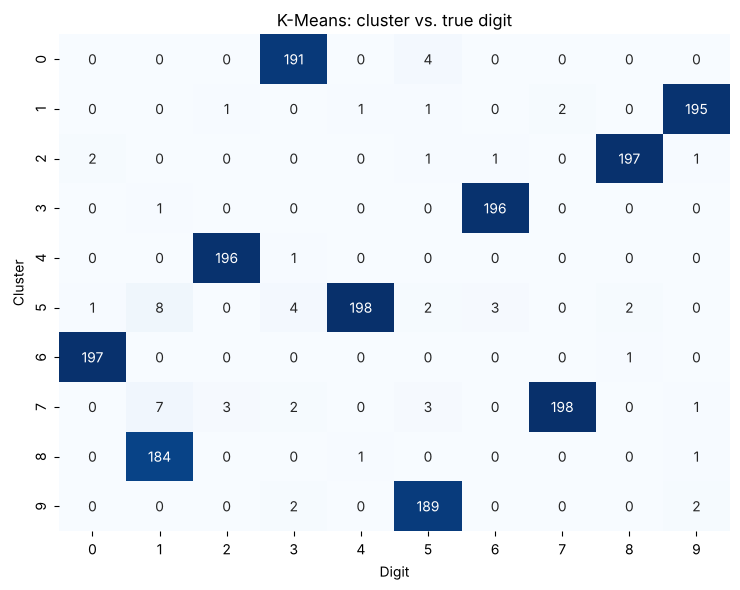

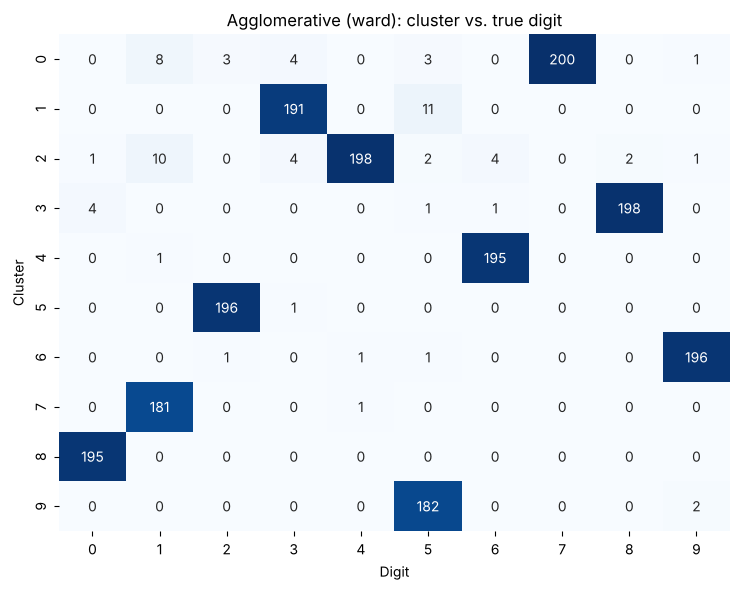

In [21]:
for name, lab in [('K-Means', km.labels_), ('Agglomerative (ward)', agg_models['ward'].labels_)]:
    mapping, ct = clu.map_clusters_to_digits(y_true, lab)
    viz.contingency_heatmap(ct, f'{name}: cluster vs. true digit')
    display(mapping.T)

> **✍️ Team observation — write this in your own words before submission.**
>
> Questions to answer:
> - Which algorithm agrees best with the true digits? Does that match the internal metrics?
> - Which digits get mixed up, and why might they look similar in feature space?
>
> _Your answer here._

## 10. Conclusion

> **✍️ Team observation — write this in your own words before submission.**
>
> Questions to answer:
> - Summarise the clustering results: which algorithm and linkage you recommend and why.
> - Trade-offs between K-Means and Agglomerative clustering (scalability, predicting new points, determinism, interpretability of the hierarchy).
>
> _Your answer here._